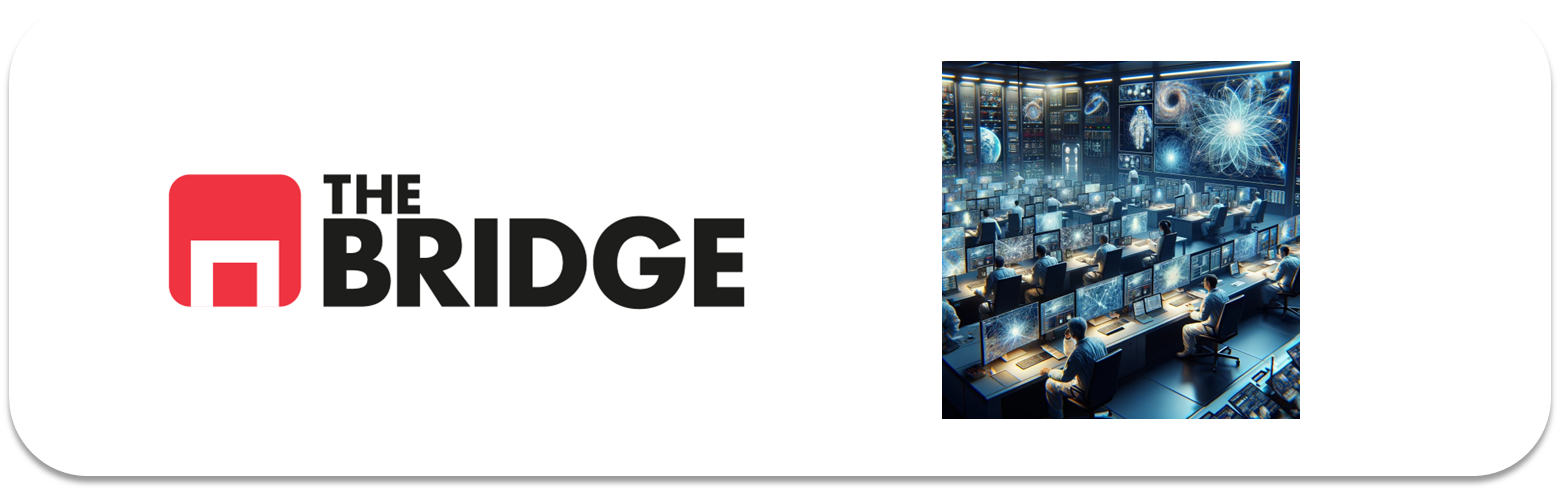

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/DS-TB-FundacionUniversia/2026-09-DS-Universia/blob/main/05_Deep_Learning/02_Convolucionales_CNN/soluciones/E01_Ejercicios_CNN_SOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

Para ejercitarte y afianzar lo aprendido sobre **Redes Convolucionales**, completa los siguientes ejercicios. Los datos se descargan directamente de Kaggle con `kagglehub` (ver Ejercicio 1), así que puedes trabajar en local o en Colab.

Las soluciones las tienes ya: intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado por si te pudieran aportar algo.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from skimage.io import imread
from sklearn.utils import shuffle
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import keras
import kagglehub
import cv2

## El problema de "Negocio"
Para este ejercicio vas a crear un clasificador automático de paisajes. Los datos son el dataset [Intel Image Classification](https://www.kaggle.com/datasets/puneet6060/intel-image-classification) de Kaggle: unas 14000 imágenes de train y 3000 de test de 6 tipos de paisaje.

NOTA: Son archivos bastante grandes (unos 350 MB comprimidos). `kagglehub` los guarda en una caché de tu carpeta de usuario (fuera del repositorio); si quieres recuperar el espacio cuando termines, borra la carpeta `.cache/kagglehub/datasets/puneet6060`.



### Ejercicio 1

Cargar las imágenes. Mira cómo están almacenados los datos. Tendrás que recorrer las carpetas, cargar las imágenes en memoria y etiquetarlas con los nombres de las carpetas. Redimensiona (resize) cada imagen (comienza el ejercicio con 32x32, para ir más rápido en las ejecuciones). Para ello:

1. Descarga las imágenes con `kagglehub` (ya viene instalado en Colab; en local `pip install kagglehub`). Fíjate en que dentro de `seg_train` y `seg_test` hay otro directorio con el mismo nombre del que ya cuelgan los directorios de cada clase de paisajes (`seg_pred` no lo vamos a usar):

```python
import kagglehub
PATH_DATA = kagglehub.dataset_download("puneet6060/intel-image-classification")
TRAIN_PATH = os.path.join(PATH_DATA, "seg_train", "seg_train")
TEST_PATH = os.path.join(PATH_DATA, "seg_test", "seg_test")
```

2. Utiliza la siguiente función para crear los X_train, y_train y X_test e y_test:

```python
def read_data(directorio, reshape_dim = (32,32)):
    X = []
    y = []
    for folder in os.listdir(directorio):
        if os.path.isdir('/'.join([directorio, folder])):
            for file in os.listdir('/'.join([directorio, folder])):

                image = imread('/'.join([directorio, folder, file]))
                image = cv2.resize(image, reshape_dim) # Redimensionamos las imágenes a 32x32

                X.append(image)
                y.append(folder)

    return np.array(X),np.array(y)
```


*Pues copiamos lo que nos dicen: primero descargamos y fijamos las rutas, después aplicamos la función a los dos directorios para tener las X y las y*

In [2]:
PATH_DATA = kagglehub.dataset_download("puneet6060/intel-image-classification")
TRAIN_PATH = os.path.join(PATH_DATA, "seg_train", "seg_train")
TEST_PATH = os.path.join(PATH_DATA, "seg_test", "seg_test")
os.listdir(TRAIN_PATH)

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

In [3]:
def read_data(directorio, reshape_dim = (32,32)):
    X = [] 
    y = []
    for folder in os.listdir(directorio):
        if os.path.isdir('/'.join([directorio, folder])):
            for file in os.listdir('/'.join([directorio, folder])):

                image = imread('/'.join([directorio, folder, file]))
                image = cv2.resize(image, reshape_dim) # Redimensionamos las imágenes a 32x32

                X.append(image)
                y.append(folder)

    return np.array(X),np.array(y)

In [4]:
X_train,y_train = read_data(TRAIN_PATH)
X_test, y_test = read_data(TEST_PATH) # Nota: podríamos dejar la creación de X_test para el final antes de usarlo y así ahorrar memoria mientras no tengamos que emplearlo

### Ejercicio 2

Haz la visualización del dataset: comprueba cuántos datos tienes, qué forma tienen, investiga las imágenes, comprueba con algunas muestras que has cargado bien los datos.


In [5]:
print('X train shape: ', X_train.shape)
print('Y train shape: ', y_train.shape)

X train shape:  (14034, 32, 32, 3)
Y train shape:  (14034,)


*14034 imágenes de 32x32 con 3 canales (color) en el train*

In [6]:
print('X test shape: ', X_test.shape)
print('Y test shape: ', y_test.shape)

X test shape:  (3000, 32, 32, 3)
Y test shape:  (3000,)


*3000 imágenes en el test*

*Adaptemos nuestra clásica función de pintado de imágenes*

In [7]:
def show_images_batch(paisajes, names = [], n_cols = 5, size_scale = 2):
    n_rows = ((len(paisajes) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * size_scale, n_rows * 1.1*size_scale))
    for index, paisaje in enumerate(paisajes):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(paisaje, cmap = "Greys")
        plt.axis("off")
        if len(names):
            plt.title(names[index])

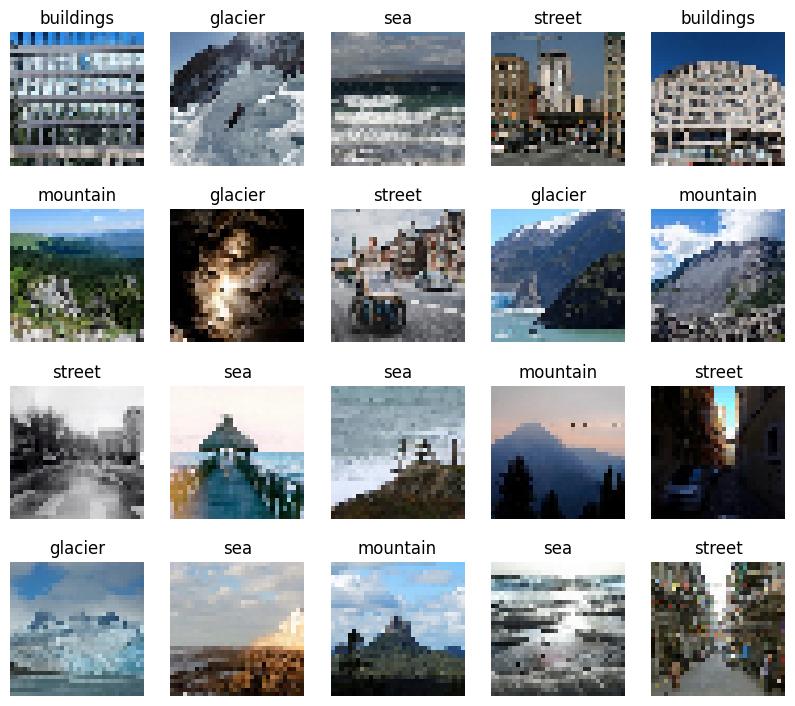

In [8]:
indices = np.random.randint(0,len(X_train),20)
show_images_batch(X_train[indices], names = y_train[indices], n_cols = 5)

*A nuestra vista, la reducción de la resolución afecta; si quieres puedes cambiar el tamaño de resolución y probar, pero ya sabes que será a costa de tiempo de computación*

### Ejercicio 3

Ahora haz un pequeño miniEDA y normaliza las features



*Veamos la distribución de cada tipo de paisaje*

In [9]:
targets = pd.Series(y_train)
targets.value_counts(True)

mountain     0.178994
glacier      0.171298
street       0.169731
sea          0.162035
forest       0.161821
buildings    0.156121
Name: proportion, dtype: float64

*Tenemos que construir un clasificador multiclase con 6 clases posibles que están más o menos balanceadas aunque hay algo más de muestras de paisajes de montaña que de edificios*

*Y ahora un clásico de la normalización de imágenes:*

In [10]:
X_train = X_train/255
X_test = X_test/255

*Recuerda que normalizar es bueno aunque todas las features estén en la misma escala: por un lado, porque las funciones de activación suelen trabajar mejor con entradas pequeñas, entre -1 y 1 o entre 0 y 1 (sobre todo tanh, sigmoide, etc.), y por otro, porque valores de entrada altos dan gradientes grandes e inestables en el descenso de gradiente con backpropagation*

### Ejercicio 4

Diseña la arquitectura de la red. Recuerda que es un problema de clasificación multiclase. Ojo con las dimensiones de la entrada. Como guía, copia o parte de la arquitectura del notebook de teoría (un par de capas Conv2D + MaxPooling2D con activación relu y después la fully connected layer)


In [11]:
# Primero definimos las capas de la red, en este caso partimos de 30 filtros de 3x3, seguido de una capa de pooling de 2x2,
# La capa Input indica el tamaño de las imágenes de entrada, en nuestro caso 32x32x3. 
# El tamaño del kernel es pequeño, lo habitual y más con resoluciones tan bajas; el número de filtros está escogido sin mucho criterio,
# juega con el número de filtros.

capas = [keras.Input(shape = X_train[0].shape),
         keras.layers.Conv2D(filters = 30, kernel_size = (3, 3),
                            padding = "same",
                            activation = 'relu'),
         keras.layers.MaxPooling2D(pool_size = (2, 2)),

# Añadimos otra capa de convolución y pooling
         keras.layers.Conv2D(filters = 15, 
                             kernel_size = (3, 3),
                             padding = "same", 
                             activation = 'relu'),
         keras.layers.MaxPooling2D(pool_size = (2, 2)),

# Añadimos una capa de flatten para convertir la salida de la capa de pooling en un vector
         keras.layers.Flatten(),

# Añadimos dos capas densas para la clasificación 
         keras.layers.Dense(units = 150, activation = 'relu'),
         keras.layers.Dense(units = 100, activation = 'relu'),

# Añadimos la capa de salida con 6 neuronas, una por cada clase
         keras.layers.Dense(6, activation = 'softmax')]

# Creamos el modelo
model = keras.Sequential(capas)

### Ejercicio 5

Escoge el resto de hiperparámetros (optimizador, learning_rate, función de pérdida, métrica...) y compila el modelo. Muestra un resumen del mismo.

*Para escoger el optimizador me fijo en el tamaño del dataset*

In [12]:
X_train.size

43112448

*Dado el tamaño podemos usar Adam, cuyos hiperparámetros por defecto suelen funcionar bastante bien*

*Como el target será un entero por clase (no un vector one-hot) usaré sparse_categorical_crossentropy y, como métrica, dado el balanceo, la accuracy.*


In [13]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

*Ahora el resumen del modelo*


In [14]:

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 30)     │           840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 15)     │         4,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 15)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 150)            │       144,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        15,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           606 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,761 (643.60 KB)

 Trainable params: 164,761 (643.60 KB)

 Non-trainable params: 0 (0.00 B)

### Ejercicio 6

Entrena el modelo reservando un 20% de los datos del entrenamiento para validar y con los callbacks que creas necesarios. NOTA: Ojo, tendrás que preparar un poco los X, y antes.



*Primero tendremos que convertir nuestro target a un ordinal :-)*

In [15]:
mapa = {tipo:indice for indice,tipo in enumerate(targets.unique())} # Reutilizando la serie que creamos para ver la distribución del target
mapa

{'buildings': 0,
 'forest': 1,
 'glacier': 2,
 'mountain': 3,
 'sea': 4,
 'street': 5}

In [16]:
y_train_num = np.array([mapa[y] for y in y_train])
y_test_num = np.array([mapa[y] for y in y_test])

*Además los datos están ordenados, por lo que debemos hacer un shuffle*

In [17]:
# Barajamos los datos: están ordenados por clase y validation_split coge siempre el último 20%
X_train, y_train_num = shuffle(X_train, y_train_num, random_state = 42)

In [18]:
history = model.fit(X_train,
                    y_train_num,
                    validation_split = 0.2,
                    epochs = 100,
                    batch_size = 32, callbacks= [keras.callbacks.EarlyStopping(patience = 10, restore_best_weights= True)]) # Queremos recuperar los pesos de la mejor época

Epoch 1/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.4803 - loss: 1.2808 - val_accuracy: 0.6462 - val_loss: 0.9195
Epoch 2/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6765 - loss: 0.8517 - val_accuracy: 0.6901 - val_loss: 0.8132
Epoch 3/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7260 - loss: 0.7441 - val_accuracy: 0.7360 - val_loss: 0.7290
Epoch 4/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7550 - loss: 0.6552 - val_accuracy: 0.7225 - val_loss: 0.7382
Epoch 5/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7878 - loss: 0.5875 - val_accuracy: 0.7645 - val_loss: 0.6765
Epoch 6/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8099 - loss: 0.5333 - val_accuracy: 0.7645 - val_loss: 0.7117
Epoch 7/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8244 - loss: 0.4853 - val_accuracy: 0.7791 - val_loss: 0.6535
Epoch 8/100
351/351 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8398 - loss: 0.4408 - val_accu


### Ejercicio 7

Representa el objeto history y comenta la evolución de tu entrenamiento.



*Observando la evolución de la métrica:*

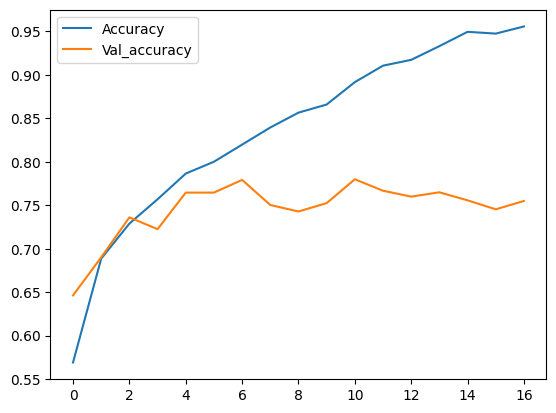

In [19]:
# Representamos el objeto history
history_df = pd.DataFrame(history.history)
plt.plot(history_df['accuracy'], label = 'Accuracy')
plt.plot(history_df['val_accuracy'], label = 'Val_accuracy')

plt.legend();

*Observando la evolución de la pérdida:*

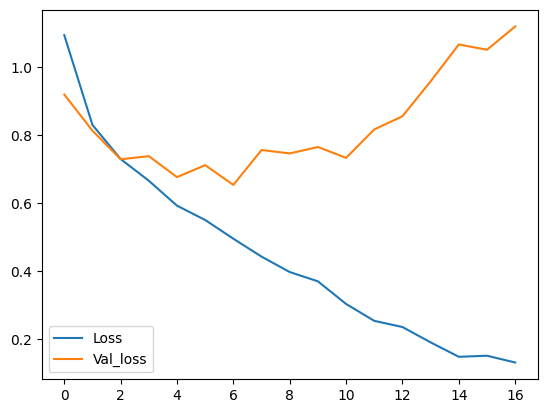

In [20]:
plt.plot(history_df['loss'], label = 'Loss')
plt.plot(history_df['val_loss'], label = 'Val_loss')

plt.legend();

*En ambas figuras se ve que a partir de la época 5-7 la validación se estanca (en torno a un 76-78% de accuracy) mientras el train sigue subiendo: sólo estamos consiguiendo hacer overfitting, y la pérdida de validación incluso empieza a subir mientras la de train sigue bajando. Gracias a `restore_best_weights` el EarlyStopping nos devuelve los pesos de la mejor época y no los de la última.*


### Ejercicio 8

Evalúa el modelo con los datos de test; además, muestra el report de clasificación y la matriz de confusión.



In [21]:
model.evaluate(X_test, y_test_num)

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7482 - loss: 0.7271


[0.6646379828453064, 0.7689999938011169]

*Un 77% de accuracy que se traduce en el siguiente report*

In [22]:
y_pred = [ np.argmax(prediction) for prediction in model.predict(X_test)]

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [23]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
inverse_map = {valor:clave for clave,valor in mapa.items()}
y_test_labels = [inverse_map[y] for y in y_test_num]
y_pred_labels = [inverse_map[y] for y in y_pred]
print(classification_report(y_test_labels, y_pred_labels))

              precision    recall  f1-score   support

   buildings       0.74      0.68      0.70       437
      forest       0.90      0.90      0.90       474
     glacier       0.78      0.69      0.73       553
    mountain       0.77      0.73      0.75       525
         sea       0.70      0.77      0.73       510
      street       0.74      0.85      0.79       501

    accuracy                           0.77      3000
   macro avg       0.77      0.77      0.77      3000
weighted avg       0.77      0.77      0.77      3000



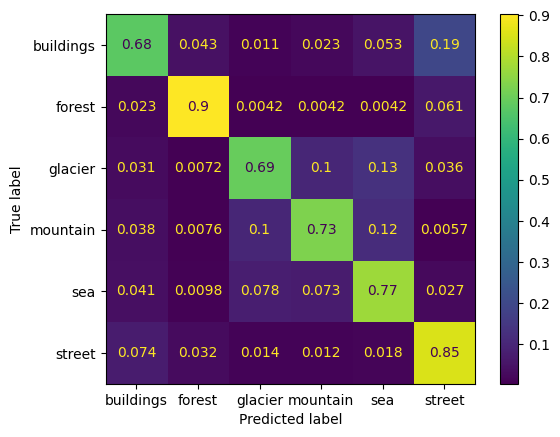

In [24]:
ConfusionMatrixDisplay.from_predictions(y_test_labels, y_pred_labels, normalize="true")

*Hay un cuadrado interesante en el centro de la matriz: glaciares, montañas y mar se confunden entre sí (glaciares y montañas son los paisajes peor detectados y se confunden sobre todo con el mar y entre ellos). El mejor clasificado son los bosques seguido de las calles. Los edificios tampoco se clasifican bien y, como era de esperar, se confunden sobre todo con las calles (casi un 20%)*


### Ejercicio 9 

Representa algunos de los paisajes donde el modelo comete errores y muestra la confianza que tenía en ellos.





In [25]:
confianza = [prediction.max() for prediction in model.predict(X_test)]

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [26]:
pred_df = pd.DataFrame({"True": y_test_labels, "Predicted": y_pred_labels, "Confianza": confianza})

In [27]:
error = pred_df["True"] != pred_df["Predicted"]
errores = pred_df[error].sort_values("Confianza", ascending = False)
errores

,True,Predicted,Confianza
180,buildings,sea,0.998802
426,buildings,sea,0.997850
88,buildings,street,0.996951
434,buildings,street,0.996725
385,buildings,street,0.995708
...,...,...,...
2629,street,sea,0.285075
1990,sea,buildings,0.278437
2121,sea,street,0.255463
1564,mountain,buildings,0.254432


In [28]:
for true_label, predicted_label in errores.iloc[0:10,0:2].values:
    print(true_label, predicted_label)

buildings sea
buildings sea
buildings street
buildings street
buildings street
mountain sea
street forest
glacier sea
sea glacier
mountain buildings


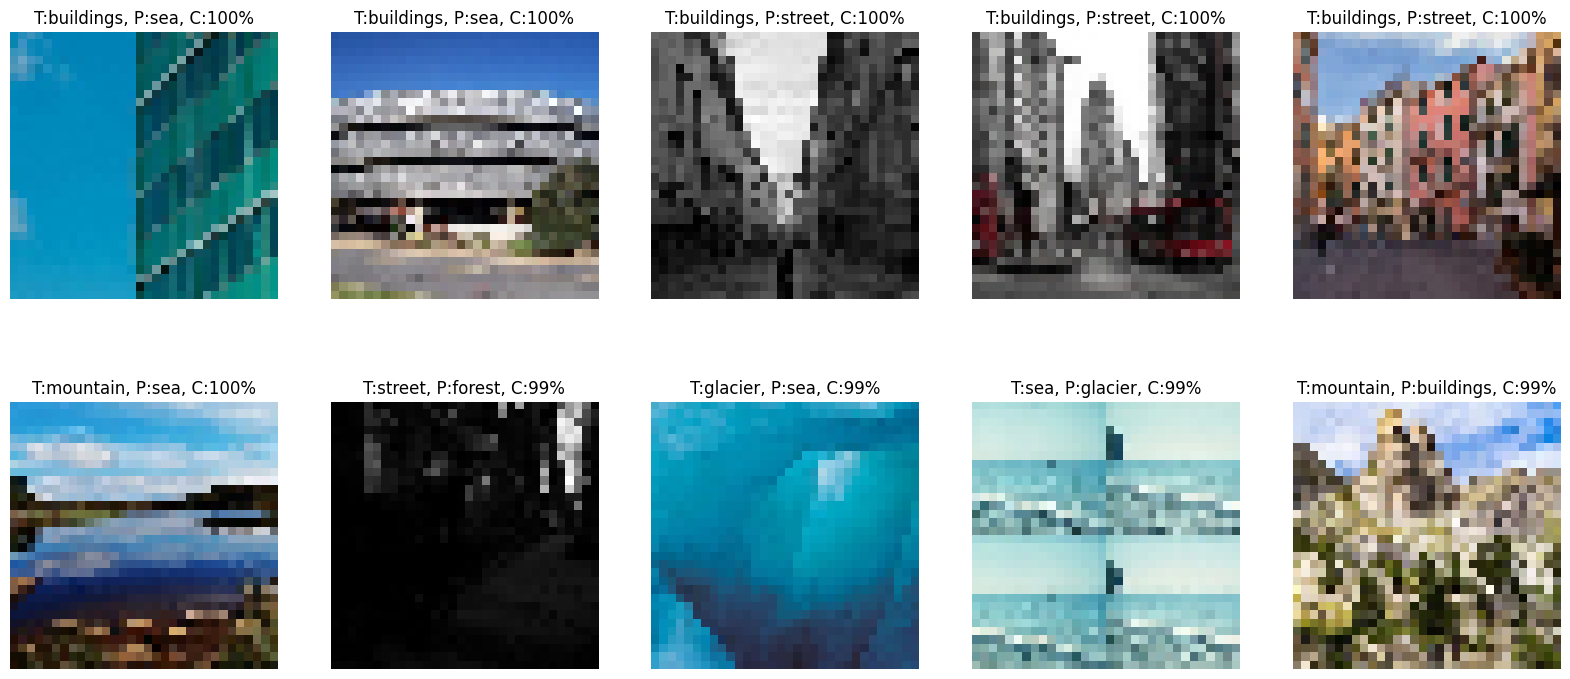

In [29]:
show_images_batch(X_test[errores.iloc[0:10].index],names= [f"T:{val1}, P:{val2}, C:{val3:.0%}" for val1,val2,val3 in errores.iloc[0:10].values], size_scale= 4)

### Ejercicio EXTRA: 

Aumenta la resolución y repite el ejercicio con la misma topología de red

In [30]:
X_train,y_train = read_data(TRAIN_PATH, (64,64))
X_test, y_test = read_data(TEST_PATH, (64,64))

*No olvidemos normalizar también estas nuevas X (si no, la red parte con entradas entre 0 y 255 y entrena mucho peor):*

In [31]:
X_train = X_train/255
X_test = X_test/255

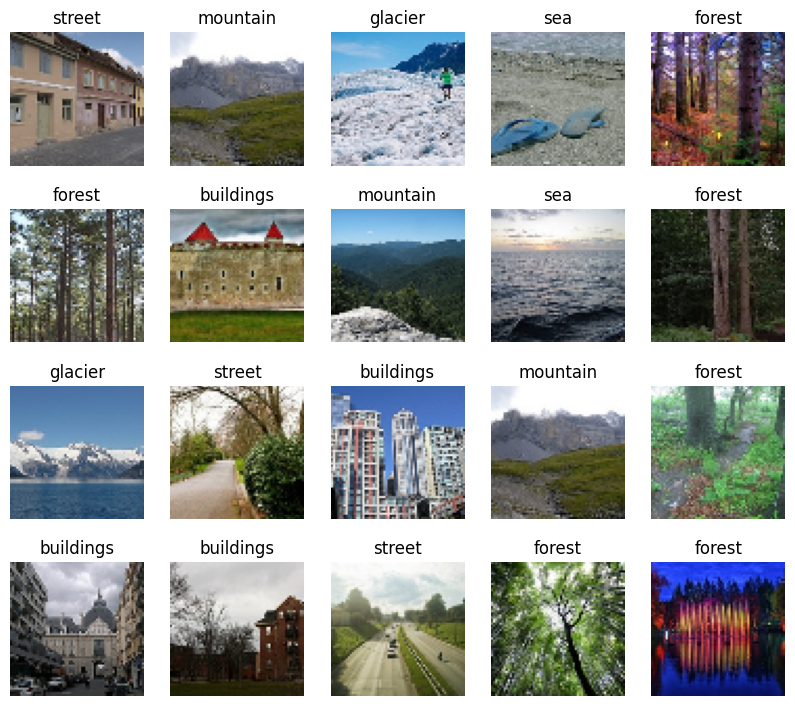

In [32]:
indices = np.random.randint(0,len(X_train),20)
show_images_batch(X_train[indices], names = y_train[indices], n_cols = 5)

In [33]:
y_train_num = np.array([mapa[y] for y in y_train])
y_test_num = np.array([mapa[y] for y in y_test])

In [34]:
X_train, y_train_num = shuffle(X_train, y_train_num, random_state = 42)

*Mantenemos la misma estructura de red (dos parejas Conv2D + MaxPooling2D y dos densas), aunque ajustamos un poco el número de filtros y de unidades al tener más resolución:*

In [35]:

capas = [keras.Input(shape = X_train[0].shape),
         keras.layers.Conv2D(filters = 32, kernel_size = (3, 3),
                            padding = "same",
                            activation = 'relu'),
         keras.layers.MaxPooling2D(pool_size = (2, 2)),

# Añadimos otra capa de convolución y pooling
         keras.layers.Conv2D(filters = 16, 
                             kernel_size = (3, 3),
                             padding = "same", 
                             activation = 'relu'),
         keras.layers.MaxPooling2D(pool_size = (2, 2)),

# Añadimos una capa de flatten para convertir la salida de la capa de pooling en un vector
         keras.layers.Flatten(),

# Añadimos dos capas densas para la clasificación 
         keras.layers.Dense(units = 300, activation = 'relu'),
         keras.layers.Dense(units = 100, activation = 'relu'),

# Añadimos la capa de salida con 6 neuronas, una por cada clase
         keras.layers.Dense(6, activation = 'softmax')]

# Creamos el modelo
model = keras.Sequential(capas)

In [36]:
model.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [37]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │     1,229,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           606 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,265,326 (4.83 MB)

 Trainable params: 1,265,326 (4.83 MB)

 Non-trainable params: 0 (0.00 B)

In [38]:
history = model.fit(X_train,
                    y_train_num,
                    validation_split = 0.2,
                    epochs = 100,
                    batch_size = 64, callbacks= [keras.callbacks.EarlyStopping(patience = 10, restore_best_weights= True)])

Epoch 1/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.4799 - loss: 1.3153 - val_accuracy: 0.6537 - val_loss: 0.8995
Epoch 2/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.6894 - loss: 0.8267 - val_accuracy: 0.7050 - val_loss: 0.7971
Epoch 3/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.7439 - loss: 0.6886 - val_accuracy: 0.7339 - val_loss: 0.7241
Epoch 4/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.7954 - loss: 0.5637 - val_accuracy: 0.7592 - val_loss: 0.6773
Epoch 5/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8337 - loss: 0.4708 - val_accuracy: 0.7574 - val_loss: 0.6883
Epoch 6/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8548 - loss: 0.3947 - val_accuracy: 0.7620 - val_loss: 0.6732
Epoch 7/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8814 - loss: 0.3381 - val_accuracy: 0.7724 - val_loss: 0.7256
Epoch 8/100
176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9014 - loss: 0.2815 - 

In [39]:
model.evaluate(X_test, y_test_num)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8002 - loss: 0.5851


[0.6461880207061768, 0.7683333158493042]

*A pesar de haber subido la resolución (y de tener una red con muchos más parámetros) obtenemos prácticamente la misma accuracy, tanto en validación como en test, y el overfitting es todavía más rápido (la accuracy de train llega casi al 99%). Más resolución da más información pero también más features que la red tiene que aprender a aprovechar: deberíamos jugar con más hiperparámetros, añadir regularización (Dropout) o hacer la red más profunda*

In [40]:
y_pred = [ np.argmax(prediction) for prediction in model.predict(X_test)]

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [41]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
inverse_map = {valor:clave for clave,valor in mapa.items()}
y_test_labels = [inverse_map[y] for y in y_test_num]
y_pred_labels = [inverse_map[y] for y in y_pred]
print(classification_report(y_test_labels, y_pred_labels))

              precision    recall  f1-score   support

   buildings       0.69      0.83      0.75       437
      forest       0.96      0.92      0.94       474
     glacier       0.78      0.65      0.71       553
    mountain       0.76      0.67      0.71       525
         sea       0.65      0.81      0.72       510
      street       0.83      0.77      0.80       501

    accuracy                           0.77      3000
   macro avg       0.78      0.77      0.77      3000
weighted avg       0.78      0.77      0.77      3000



In [42]:
confianza = [prediction.max() for prediction in model.predict(X_test)]
pred_df = pd.DataFrame({"True": y_test_labels, "Predicted": y_pred_labels, "Confianza": confianza})

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


In [43]:
error = pred_df["True"] != pred_df["Predicted"]
errores = pred_df[error].sort_values("Confianza", ascending = False)
errores

,True,Predicted,Confianza
2319,sea,buildings,0.999402
434,buildings,street,0.998790
79,buildings,forest,0.997852
119,buildings,street,0.997477
2805,street,forest,0.995724
...,...,...,...
2680,street,sea,0.309933
2421,sea,buildings,0.303590
1776,mountain,sea,0.303337
943,glacier,sea,0.302089


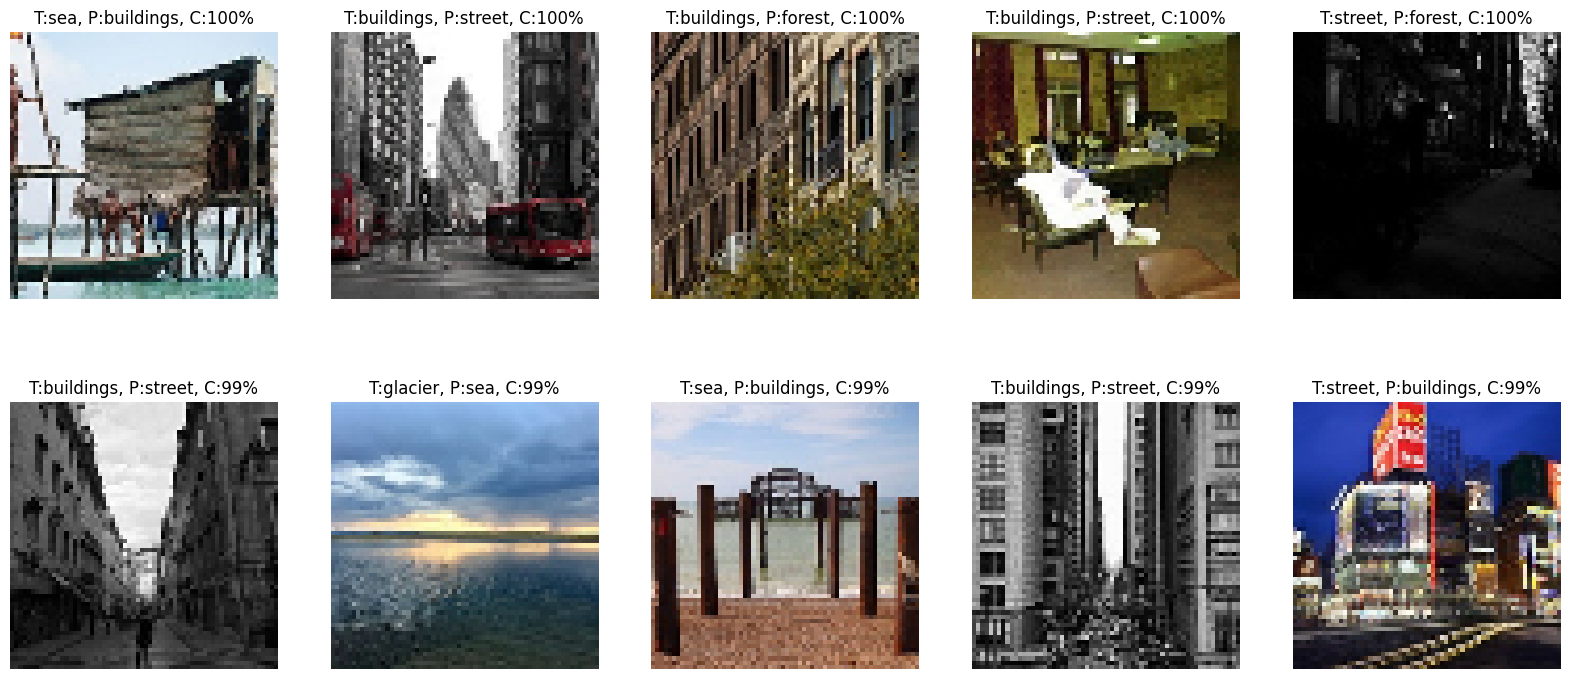

In [44]:
show_images_batch(X_test[errores.iloc[0:10].index],names= [f"T:{val1}, P:{val2}, C:{val3:.0%}" for val1,val2,val3 in errores.iloc[0:10].values], size_scale= 4)

*A veces piensa uno si no estará mal etiquetado :-)*